# Bagging Ensemble

- Bagging is made of two words: **B**ootstrap and **Agg**regation.

- So there will be two steps in the bagging ensemble:
    1. **Bootstrap**: Randomly sample the training data with replacement to create multiple datasets. Each dataset will be used to train a base model.
    2. **Aggregation**: Combine the predictions of all the base models to make a final prediction. For classification, we can take the majority vote, and for regression, we can take the mean of all the predictions.

- Here we have to ensure that all the base models will be of same algorithm, but they will be trained on different datasets. This will ensure that the base models are diverse and will not overfit the training data.

- So, bootstrap in the given dataset D, and form multiple datasets D1, D2, D3, ..., Dn. And train each base model on a different dataset.

- Eg. m1 is trained on D1, m2 is trained on D2, m3 is trained on D3, and so on.

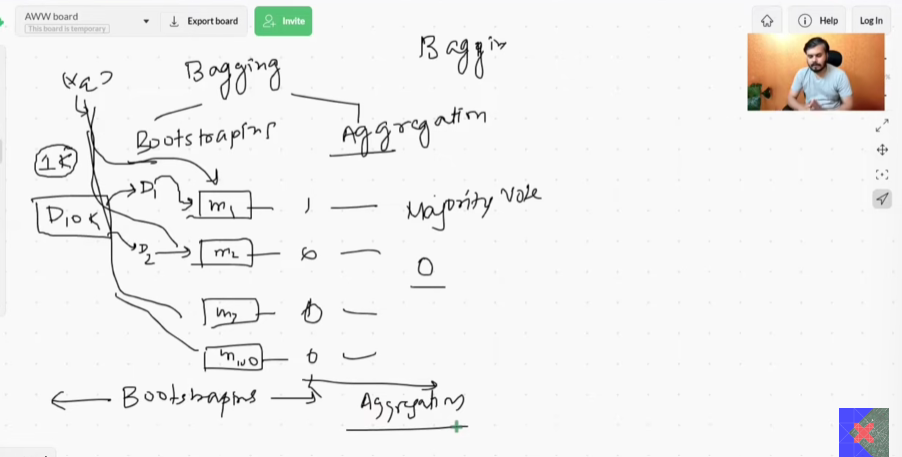

- Now when a query point comes, we will get the predictions from all the base models and then take the majority vote for classification or mean for regression. (This process is called **aggregation**)

### Why does bagging work?

- Same probaility logic as voting ensemble so the resulting combined model is better than any individual model, but here we are ensuring that the base models are diverse by training them on different datasets. This will ensure that the base models are not correlated.

- See detailed explanation [here](../D63-Voting-Ensemble/1-Intro.ipynb)


## Bagging ki khas baakt kya h?? Why does the performance increase after bagging?

- Everything is dependent on Bias Variance tradeoff.

- In general, most of the ML algorithms will either high bial and low variance or low bias and high variance.

- But if you use bagging properly then you can get combined model with **low bias and low variance**. This is the main reason why bagging works.

### To achieve Low bias and low variance:

- Take a **base model** with **low bias and high variance**, and then use bagging to reduce the variance. This will give you a combined model with low bias and low variance.

- Eg. of model wtih low bias and high variance: Decision Tree, KNN, etc.

- A fully grown (`max_depth=None`) decision tree will have accuracy close to **100%** on the training data, so it has **low bias** and because of overfitting, it has **high variance**.

### How does bagging reduce variance?

- Suppose in a 10K sample dataset, and 3 DT models, we are giving 5K rows to each model by bootstraping

- But now suppose we changed 100 rows in the 10K datasets, that are very different from the previous 100 rows

- If it would be a single DT model, then its logic would have changed because of the changed 100 rows

- But here in bagging, we have 3 DT models, and we are bootstrapping the dataset, so esa kvhi hoga hi nhi ki ek hi tree to 100 k 100 changed rows mil gaye, may be kisime 10 changed rows mil gaye, kisi me 50, kisi me 0 and so on

- So, since data mei changes huye hi nhi jada toh base models ka behaviour change hi nhi hoga

- So, it is kind of that the impact fo changed rows is distributed among the base models so variance of the base models is reduced and the combined model will have low variance.

- So even on changing the trainging data, there is no change in the combined model, so it have low variance.

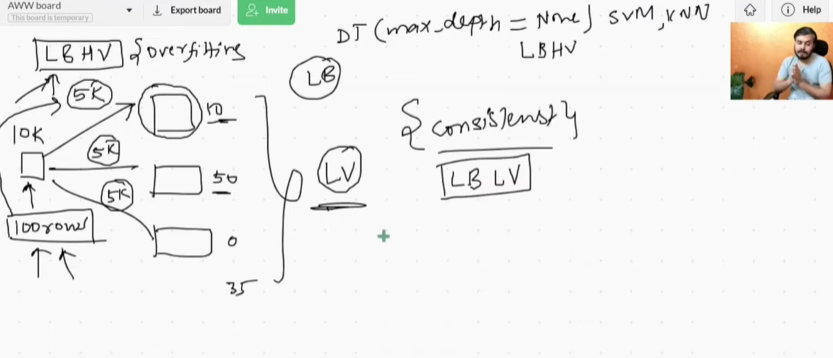

# When to use bagging?

- Whenever you are dealing with a model with low bias and high variance, then you can use bagging to reduce the variance and get a combined model with low bias and low variance.



# Types of bagging Ensemble:
### 1. Bagging
- Here, we perform **row sampling with replacement**.
- Suppose we pick row 1 and put it back into the dataset. We can pick row 1 again in the next draw.
- Therefore, the same row can appear multiple times in a single bootstrap sample.
- Different base models are trained on different bootstrap samples.
### 2. Pasting
- Here, we perform row sampling without replacement.
- Once a row is selected, it cannot be selected again within the same sample.
- Therefore, a row cannot appear more than once in a particular base model's training dataset.
- However, the same row can appear in different base models.
- Different base models are trained on different subsets of rows
### 3. Random Subspaces
- Here we **don't do row sampling**, instead we do **column sampling without replacement** . So each base model will have different columns/features. This is useful when we have a large number of features and we want to reduce the dimensionality of the data.
### 4. Random Patches (Bagging/Pasting + Random Subspaces)
- Here we do **both row (with/without replacement) and column (without replacement) sampling**. So each base model will have different rows and different columns/features. This is useful when we have a large number of features and we want to reduce the dimensionality of the data, and also when we have a large number of samples and we want to reduce the size of the data.

- We only use random patches and random subspaces when we have a large number of features, otherwise we can use bagging or pasting.

See code at [here](1.2-bagging-learning-tool.ipynb)

## NOTE:

<text style="color:red">The primary reason Bagging reduces variance is that we train multiple models on different bootstrap samples of the original dataset and then aggregate their predictions. So even if we add new samples in the training set, each base model will not get all the changed data so the impact of the changed data is distributed across all the base models.</text>

# OOB (Out of Bag) Samples

- Statistically, in a bootstrap sample, only **63.2%** of the original dataset will be sampled and the remaining **36.8%** of the original dataset will be left out and will never be seen by any of the base models. These left out samples are called **Out of Bag (OOB) samples**.

- So we can use these OOB samples to evaluate the performance of the bagging ensemble without using a separate validation set.